# Ordered Horizontal Bar Chart

**Family:** Ranking &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Ranking:* Use when an item's position in an ordered list matters more than its absolute value.

## Design purpose

Horizontal bars sorted from largest to smallest. Sorting turns comparison into a ranking that reads top to bottom, and horizontal bars leave room for long category labels.

## When to use

- Rank categories by a single value (top 10 products, countries, causes)
- Show categories with long names
- Highlight where one item of interest sits in the ranking

## Avoid when

- The categories have a natural order (months, age bands): keep that order instead
- There are more than ~25 categories (show the top N and fold the rest into 'Other')

## Alternatives

- Lollipop chart
- Cleveland dot plot
- Ordered column chart

## Design tips

- Put the largest value at the top
- Use one color, and highlight only the item that matters, with the rest in gray
- Label values directly and drop the x-axis when there are few bars

## Example

Top 12 programming languages by share of developers (synthetic survey), highlighting Python.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
langs = ["JavaScript", "Python", "SQL", "TypeScript", "Java", "C#", "C++", "Go",
         "Rust", "PHP", "Kotlin", "Swift"]
share = [62.3, 51.0, 48.7, 38.5, 30.1, 27.0, 22.4, 14.2, 13.1, 12.0, 9.4, 5.1]
df = pd.DataFrame({"language": langs, "share_pct": share}).sort_values("share_pct")
df.tail()

,language,share_pct
4,Java,30.1
3,TypeScript,38.5
2,SQL,48.7
1,Python,51.0
0,JavaScript,62.3


### Plot

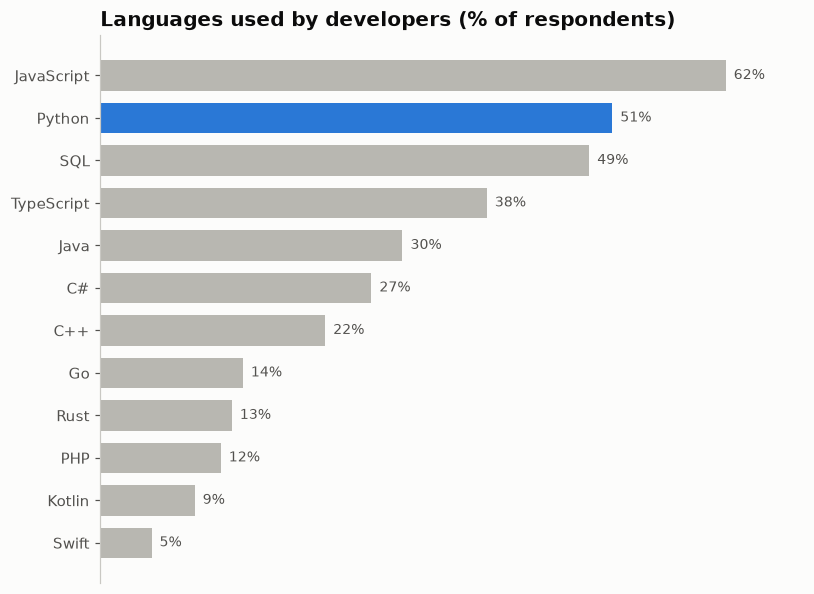

In [3]:
fig, ax = plt.subplots(figsize=(7.5, 5.5))
colors = [PALETTE[0] if l == "Python" else GRAY for l in df["language"]]
ax.barh(df["language"], df["share_pct"], color=colors, height=0.72)
for y, v in enumerate(df["share_pct"]):
    ax.text(v + 0.8, y, f"{v:.0f}%", va="center", fontsize=9, color="#52514e")
ax.set_xlim(0, 70)
ax.xaxis.set_visible(False)
ax.spines["bottom"].set_visible(False)
ax.grid(False)
ax.set_title("Languages used by developers (% of respondents)")
fig.tight_layout()
plt.show()

## How to read it

Bars run from most used (top) to least used. Python is highlighted in blue and ranks second.

---
Standalone script: [`ordered_bar.py`](ordered_bar.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)